# Eksplorasi gambar dokumen

Notebook ini memeriksa dataset klasifikasi dokumen dengan 16 kategori. Data terdiri dari 32.003 gambar train dan 7.994 gambar test. Output tabel dan gambar di bawah berasal dari run Kaggle yang dikirim bersama notebook ini.

Analisis mencakup kelengkapan CSV, jumlah gambar per kelas, contoh gambar, ukuran gambar, dan perbandingan train-test. Notebook ini tidak melakukan training atau mengubah label. Untuk menjalankan ulang, tambahkan dataset di Kaggle dan jalankan sel dari atas ke bawah.


In [1]:
from pathlib import Path
DATA_DIR = Path('/kaggle/input/competitions/document-image-classification-sd234504')
TRAIN_DIR = DATA_DIR / 'train/train'   # Langsung berisi folder kategori.
TEST_DIR = DATA_DIR / 'test/test'      # Langsung berisi gambar test.
OUTPUT_DIR = Path('/kaggle/working/eda')
SEED = 42
SAMPLES_PER_CLASS = 4
# False: hanya metadata. True: periksa pemuatan piksel halaman pertama juga.
READ_PIXELS = False


## 1. Persiapan

Import library untuk membaca tabel dan gambar serta membuat grafik. `OUTPUT_DIR` digunakan untuk menyimpan tabel dan gambar hasil analisis. Pemeriksaan EDA ini tidak membutuhkan GPU.


In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
CLASS_NAMES = ['advertisement', 'budget', 'email', 'file_folder', 'form',
               'handwritten', 'invoice', 'letter', 'memo', 'news_article',
               'presentation', 'questionnaire', 'resume',
               'scientific_publication', 'scientific_report', 'specification']
CLASS_TO_LABEL = dict(zip(CLASS_NAMES, range(16)))
for folder in [DATA_DIR, TRAIN_DIR, TEST_DIR]:
    if not folder.is_dir():
        raise FileNotFoundError(f'Folder tidak ditemukan: {folder}. Periksa pengaturan path.')
print('Output EDA:', OUTPUT_DIR)


Output EDA: /kaggle/working/eda


## 2. Membaca dan memeriksa CSV

Baca metadata train, test, dan sample submission. Periksa kolom wajib, nilai kosong, ID berulang, serta kecocokan nama kelas dan label.

Hasil pemeriksaan menunjukkan 32.003 baris train, 7.994 baris test, dan 16 kelas. Semua pemeriksaan pada tabel audit berstatus OK. ID dan urutan test juga sesuai dengan sample submission. Keunikan ID belum membuktikan keunikan isi gambar.


In [3]:
train_df = pd.read_csv(DATA_DIR / 'train.csv', dtype={'id': str})
test_df = pd.read_csv(DATA_DIR / 'test.csv', dtype={'id': str})
submission_df = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype={'id': str})
tables = {'train': train_df, 'test': test_df, 'sample_submission': submission_df}
required = {'train': ['id','filename','class_name','label'],
            'test': ['id','filename'], 'sample_submission': ['id','label']}
for name, df in tables.items():
    if df.empty or not set(required[name]).issubset(df.columns):
        raise ValueError(f'{name} kosong atau kolom wajib tidak lengkap.')
    print(f'{name}: {len(df):,} baris')
    display(df.head())


train: 32,003 baris


,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


test: 7,994 baris


,id,filename
0,test_00001,test/test_00001.tif
1,test_00002,test/test_00002.tif
2,test_00003,test/test_00003.tif
3,test_00004,test/test_00004.tif
4,test_00005,test/test_00005.tif


sample_submission: 7,994 baris


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,0
3,test_00004,0
4,test_00005,0


In [4]:
audit_rows = []
def add_check(dataset, check, passed, detail):
    """Catat satu hasil pemeriksaan metadata tanpa mengubah tabel sumber."""
    audit_rows.append({'dataset': dataset, 'pemeriksaan': check,
                       'status': 'OK' if passed else 'PERIKSA', 'detail': str(detail)})

for name, df in tables.items():
    reference = 32003 if name == 'train' else 7994
    add_check(name, 'Jumlah baris', len(df) == reference, f'{len(df)}; acuan {reference}')
    add_check(name, 'Nama kolom', set(df.columns) == set(required[name]), list(df.columns))
    for column in required[name]:
        values = df[column].astype('string')
        blank = values.isna() | values.str.strip().eq('').fillna(False)
        add_check(name, f'Nilai kosong {column}', not blank.any(), int(blank.sum()))
    for column in ['id', 'filename']:
        if column in df:
            n = int(df[column].duplicated(keep=False).sum())
            add_check(name, f'Baris dengan {column} berulang', n == 0, n)
labels = pd.to_numeric(train_df['label'], errors='coerce')
valid_labels = labels.isin(range(16))
expected = train_df['class_name'].map(CLASS_TO_LABEL)
valid_mapping = valid_labels & expected.notna() & labels.eq(expected)
add_check('train', 'Label integer 0-15', valid_labels.all(), int((~valid_labels).sum()))
add_check('train', 'Pemetaan kategori-label', valid_mapping.all(), int((~valid_mapping).sum()))
add_check('train', 'Semua kelas tersedia', set(train_df['class_name'].dropna()) == set(CLASS_NAMES), train_df['class_name'].nunique())
add_check('test', 'Kumpulan ID sama dengan submission', set(test_df['id']) == set(submission_df['id']), 'Kumpulan ID')
add_check('test', 'Urutan ID sama dengan submission', test_df['id'].equals(submission_df['id']), 'Urutan ID')
add_check('sample_submission', 'Urutan kolom', list(submission_df.columns) == ['id','label'], list(submission_df.columns))
metadata_audit = pd.DataFrame(audit_rows)
display(metadata_audit)
metadata_audit.to_csv(OUTPUT_DIR / 'metadata_audit.csv', index=False)
train_df.loc[~valid_mapping].to_csv(OUTPUT_DIR / 'invalid_train_labels.csv', index=False)


,dataset,pemeriksaan,status,detail
0,train,Jumlah baris,OK,32003; acuan 32003
1,train,Nama kolom,OK,"['id', 'filename', 'class_name', 'label']"
2,train,Nilai kosong id,OK,0
3,train,Nilai kosong filename,OK,0
4,train,Nilai kosong class_name,OK,0
5,train,Nilai kosong label,OK,0
6,train,Baris dengan id berulang,OK,0
7,train,Baris dengan filename berulang,OK,0
8,test,Jumlah baris,OK,7994; acuan 7994
9,test,Nama kolom,OK,"['id', 'filename']"


## 3. Jumlah gambar setiap kelas

Kelas terbesar adalah `scientific_publication` dengan 2.056 gambar. Kelas terkecil adalah `questionnaire` dengan 1.948 gambar. Rasio jumlah kelas terbesar terhadap terkecil adalah sekitar 1,055.

Jumlah sampel antarkelas relatif serupa, dengan proporsi sekitar 6,09% sampai 6,42%. Hasil ini menjadi dasar penggunaan pembagian train-validation yang menjaga proporsi kelas.


,label,class_name,jumlah,persentase
0,0,advertisement,2012,6.29
1,1,budget,2004,6.26
2,2,email,2013,6.29
3,3,file_folder,2022,6.32
4,4,form,2005,6.27
5,5,handwritten,2026,6.33
6,6,invoice,1982,6.19
7,7,letter,1972,6.16
8,8,memo,1994,6.23
9,9,news_article,1971,6.16


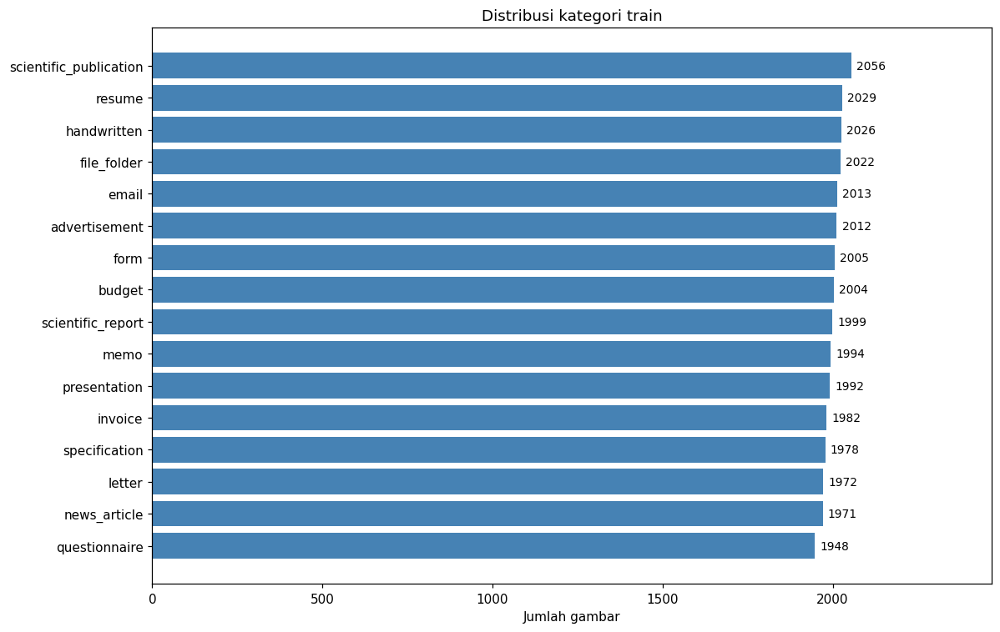

Rasio terbesar / terkecil: 1.055


In [5]:
class_counts = train_df['class_name'].value_counts().reindex(CLASS_NAMES, fill_value=0)
class_distribution = pd.DataFrame({'label': range(16), 'class_name': CLASS_NAMES,
                                   'jumlah': class_counts.to_numpy()})
class_distribution['persentase'] = class_distribution['jumlah'] / len(train_df) * 100
display(class_distribution.round(2))
class_distribution.to_csv(OUTPUT_DIR / 'class_distribution.csv', index=False)
plot_data = class_distribution.sort_values('jumlah')
fig, ax = plt.subplots(figsize=(11,7))
bars = ax.barh(plot_data['class_name'], plot_data['jumlah'], color='steelblue')
ax.bar_label(bars, padding=4, fontsize=9)
ax.set_xlim(0, max(1, plot_data['jumlah'].max()) * 1.2)
ax.set_xlabel('Jumlah gambar')
ax.set_title('Distribusi kategori train')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=150)
plt.show()
plt.close(fig)
if class_counts.min() > 0:
    print(f'Rasio terbesar / terkecil: {class_counts.max() / class_counts.min():.3f}')
else:
    print('Ada kelas referensi yang tidak ditemukan.')


## 4. Memeriksa lokasi file

Susun lokasi gambar dari nama kategori dan filename. Pemeriksaan ini memastikan file pada CSV dapat ditemukan di folder input. Keberadaan file belum memastikan gambar tersebut dapat dibuka.


In [6]:
def filename_only(value):
    """Ambil nama file dari path Linux atau Windows."""
    return str(value).replace(chr(92), '/').split('/')[-1]

train_df['path'] = train_df.apply(lambda row: str(TRAIN_DIR / str(row['class_name']) / filename_only(row['filename'])), axis=1)
test_df['path'] = test_df['filename'].map(lambda value: str(TEST_DIR / filename_only(value)))
for name, df in [('train',train_df), ('test',test_df)]:
    df['file_exists'] = df['path'].map(lambda path: Path(path).is_file())
    missing = df.loc[~df['file_exists']]
    print(f'{name}: {df["file_exists"].sum():,}/{len(df):,} file ditemukan')
    missing.to_csv(OUTPUT_DIR / f'{name}_missing_files.csv', index=False)
    if not missing.empty:
        display(missing[['id','path']].head(10))


train: 32,003/32,003 file ditemukan
test: 7,994/7,994 file ditemukan


## 5. Contoh gambar setiap kelas

Tampilkan empat contoh acak per kelas dengan seed tetap agar pemilihan sampel dapat diulang. Galeri membantu melihat tata letak, ukuran teks, dan variasi dalam kategori yang sama.

Setiap TIFF ditampilkan pada halaman pertama. Gambar yang gagal dibaca diberi keterangan dan dicatat. Sampel ini digunakan untuk pengamatan awal, bukan untuk menyimpulkan seluruh kualitas gambar.


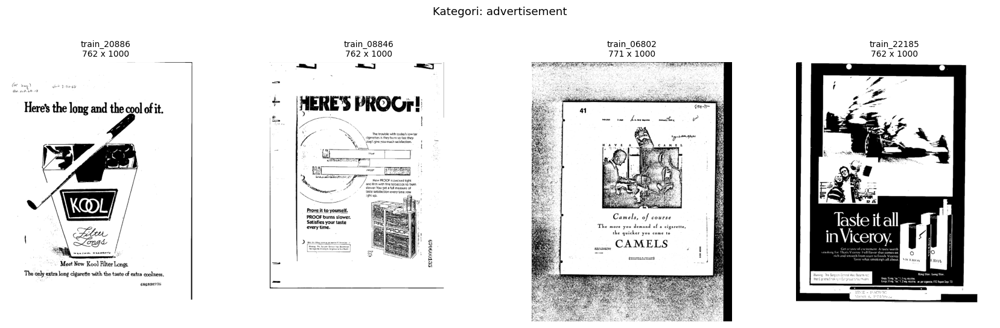

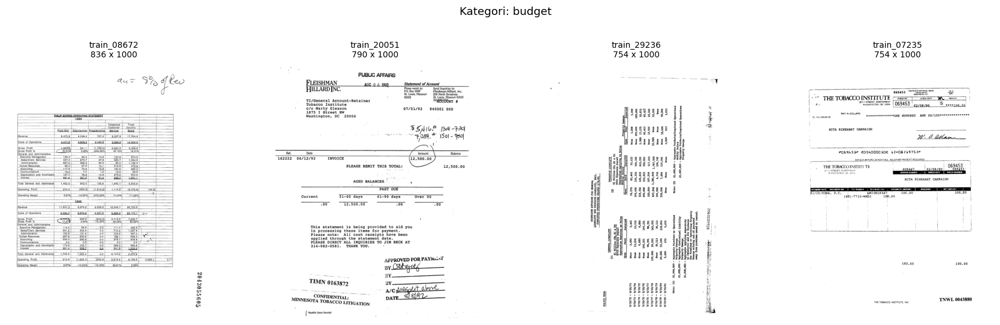

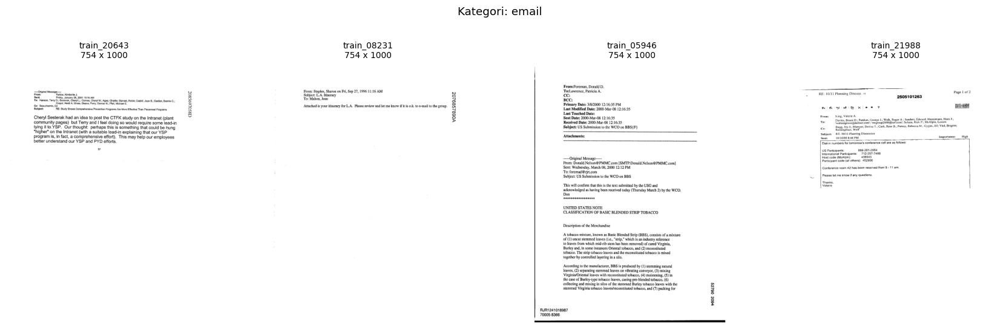

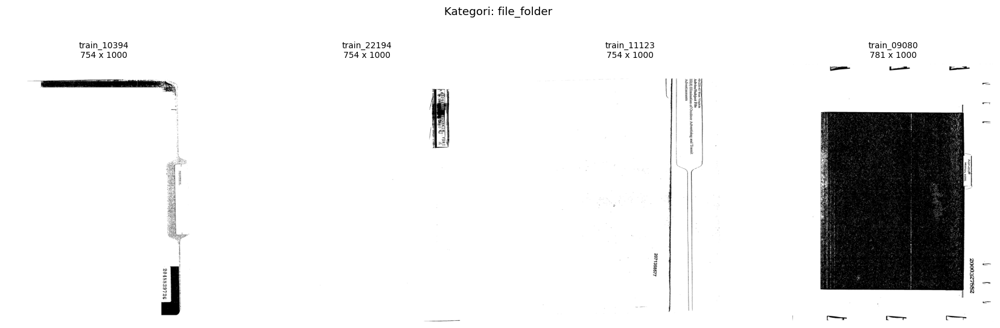

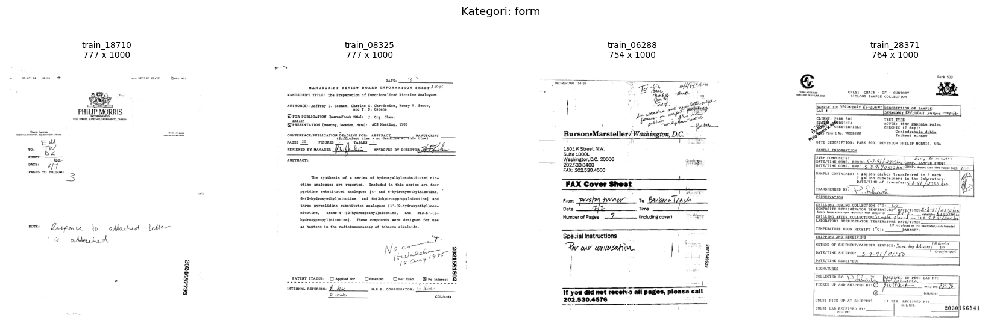

...

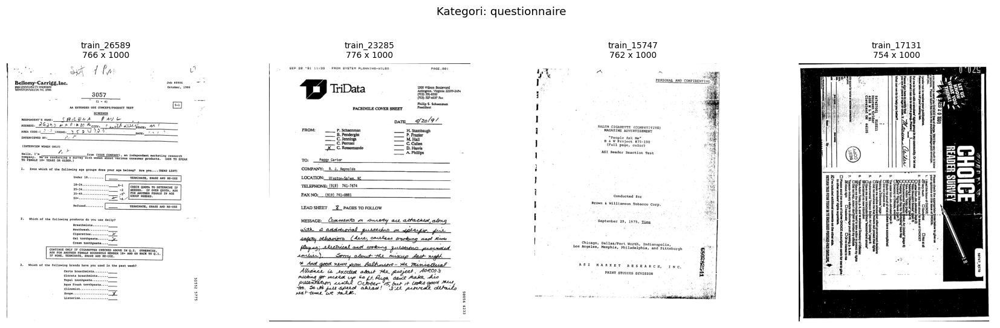

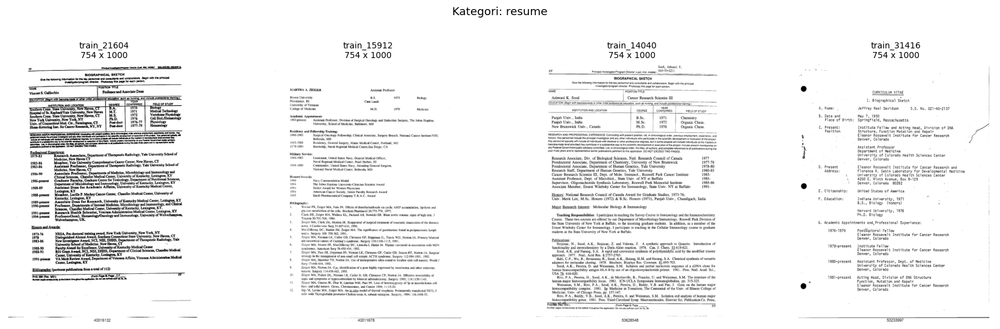

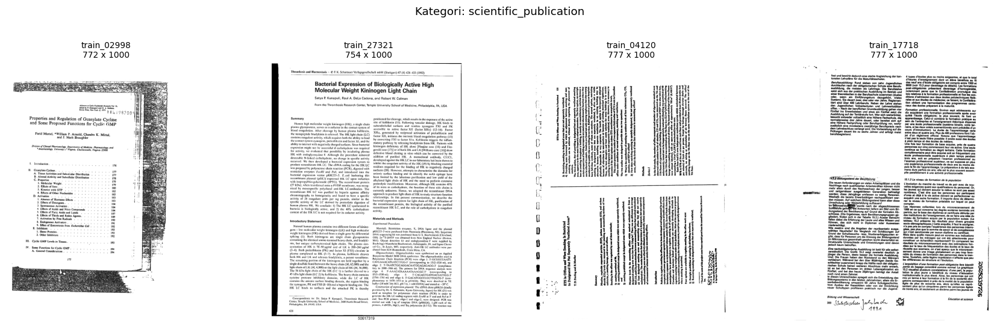

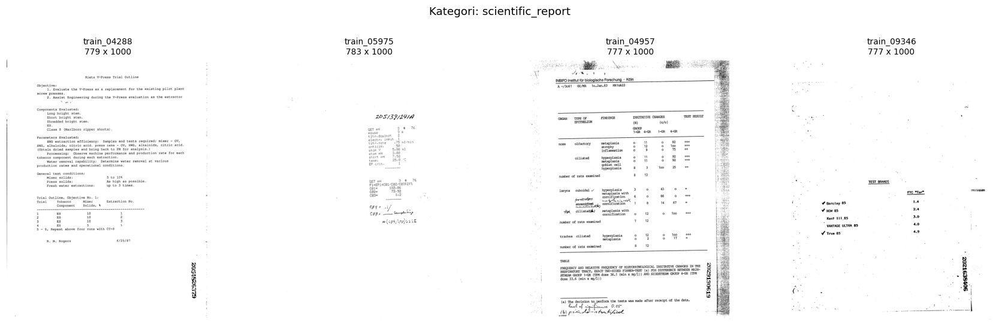

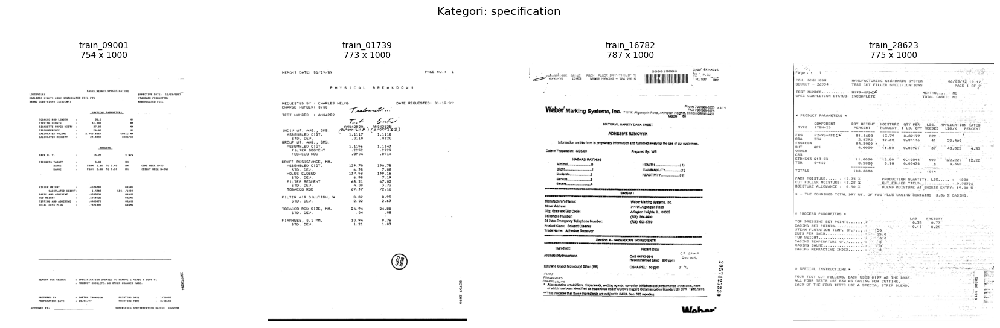

In [7]:
def read_rgb(path):
    """Baca halaman pertama TIFF dan kembalikan gambar RGB berorientasi EXIF."""
    with Image.open(path) as image:
        image.seek(0)
        result = ImageOps.exif_transpose(image).convert('RGB')
        result.load()
        return result

gallery_errors = []
def show_gallery(df, title, output_name, n=4, random_sample=False):
    """Tampilkan dan simpan sampel gambar, lalu catat file yang gagal dibaca."""
    if df.empty:
        print(f'{title}: tidak ada sampel.')
        return
    selected = df.sample(min(n,len(df)), random_state=SEED) if random_sample else df.head(n)
    columns = min(4, len(selected))
    rows = (len(selected) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4*columns,5*rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (_, row) in zip(axes.ravel(), selected.iterrows()):
        try:
            image = read_rgb(row['path'])
            ax.imshow(image)
            ax.set_title(f'{row["id"]}\n{image.width} x {image.height}', fontsize=9)
        except Exception as exc:
            ax.set_title(str(row['id']), fontsize=9)
            ax.text(.5,.5,f'Gagal dibaca\n{type(exc).__name__}', ha='center',va='center',transform=ax.transAxes)
            gallery_errors.append({'id':row['id'],'path':row['path'],'error':str(exc)})
    fig.suptitle(title)
    fig.tight_layout(rect=[0,0,1,.94])
    fig.savefig(OUTPUT_DIR / output_name, dpi=120)
    plt.show()
    plt.close(fig)

for name in CLASS_NAMES:
    show_gallery(train_df.loc[train_df['class_name'].eq(name)],
                 f'Kategori: {name}', f'gallery_{name}.png',
                 n=SAMPLES_PER_CLASS, random_sample=True)
pd.DataFrame(gallery_errors, columns=['id','path','error']).to_csv(OUTPUT_DIR / 'gallery_errors.csv', index=False)


## 6. Ukuran, mode warna, dan halaman TIFF

Sebanyak 32.002 file train berhasil dibaca metadatanya dan satu file gagal, yaitu `train_08795`. Seluruh 7.994 file test berhasil dibaca metadatanya.

Pada run ini, `READ_PIXELS=False`. Karena itu, status OK berarti metadata dapat dibaca, bukan jaminan seluruh piksel bebas kerusakan. Peringatan EXIF dicatat terpisah dari kegagalan pembacaan.


In [8]:
def collect_metadata(df, dataset_name):
    """Baca metadata gambar dan catat kegagalan serta peringatan TIFF."""
    records = []
    for row in tqdm(df.itertuples(index=False), total=len(df), desc=f'Metadata {dataset_name}'):
        record = dict(dataset=dataset_name,id=row.id,path=row.path,width=None,height=None,
                      aspect_ratio=None,megapixels=None,file_size_kb=None,color_mode=None,
                      n_frames=None,status='ok',error='',warning='')
        caught = []
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                record['file_size_kb'] = Path(row.path).stat().st_size / 1024
                with Image.open(row.path) as image:
                    image.seek(0)
                    if READ_PIXELS:
                        image.load()
                    w,h = image.size
                    record.update(width=w,height=h,aspect_ratio=w/h,megapixels=w*h/1e6,
                                  color_mode=image.mode,n_frames=getattr(image,'n_frames',1))
        except Exception as exc:
            record['status'] = 'read_error'
            record['error'] = f'{type(exc).__name__}: {exc}'
        record['warning'] = ' | '.join(dict.fromkeys(str(item.message) for item in caught))
        records.append(record)
    return pd.DataFrame(records)

train_metadata = collect_metadata(train_df, 'train')
test_metadata = collect_metadata(test_df, 'test')
image_metadata = pd.concat([train_metadata,test_metadata],ignore_index=True)
valid_metadata = image_metadata.loc[image_metadata['status'].eq('ok')].copy()
image_metadata.to_csv(OUTPUT_DIR / 'image_metadata.csv',index=False)
image_metadata.loc[image_metadata['status'].ne('ok')].to_csv(OUTPUT_DIR / 'image_errors.csv',index=False)
image_metadata.loc[image_metadata['warning'].ne('')].to_csv(OUTPUT_DIR / 'image_warnings.csv',index=False)
display(pd.crosstab(image_metadata['dataset'],image_metadata['status']))
display(image_metadata.loc[image_metadata['status'].ne('ok'),['dataset','id','error']].head(20))
if any(valid_metadata.loc[valid_metadata['dataset'].eq(name)].empty for name in ['train','test']):
    raise ValueError('Tidak ada metadata yang dapat dibaca untuk train atau test. Periksa path dan error.')


Metadata train:   0%|          | 0/32003 [00:00<?, ?it/s]

Metadata test:   0%|          | 0/7994 [00:00<?, ?it/s]

status,ok,read_error
dataset,,
test,7994,0
train,32002,1


,dataset,id,error
8794,train,train_08795,UnidentifiedImageError: cannot identify image ...


## 7. Perbandingan gambar train dan test

Pada gambar yang berhasil diperiksa, seluruh tinggi gambar adalah 1.000 piksel. Lebar train berkisar 606 sampai 2.542 piksel, sedangkan lebar test berkisar 606 sampai 1.473 piksel. Resolusi yang paling sering muncul pada keduanya adalah 754 x 1.000 piksel.

Seluruh gambar yang berhasil diperiksa menggunakan mode grayscale `L` dan memiliki satu halaman TIFF. Lebar median train adalah 762 piksel dan test 754 piksel.

Histogram menggunakan kepadatan agar perbedaan jumlah sampel tidak menentukan tinggi grafik. Kesamaan ukuran dan warna belum membuktikan kesamaan isi atau distribusi kelas test.


width                 height                 aspect_ratio         \
           min median     max     min  median     max          min median   
dataset                                                                     
test     606.0  754.0  1473.0  1000.0  1000.0  1000.0        0.606  0.754   
train    606.0  762.0  2542.0  1000.0  1000.0  1000.0        0.606  0.762   

               megapixels                
           max        min median    max  
dataset                                  
test     1.473      0.606  0.754  1.473  
train    2.542      0.606  0.762  2.542

Resolusi terbanyak: train


,width,height,jumlah
92,754.0,1000.0,15060
115,777.0,1000.0,3843
100,762.0,1000.0,2745
110,772.0,1000.0,774
109,771.0,1000.0,671
140,802.0,1000.0,540
116,778.0,1000.0,437
119,781.0,1000.0,356
117,779.0,1000.0,323
118,780.0,1000.0,304


Resolusi terbanyak: test


,width,height,jumlah
58,754.0,1000.0,3839
80,777.0,1000.0,974
65,762.0,1000.0,666
75,772.0,1000.0,174
74,771.0,1000.0,173
105,802.0,1000.0,135
81,778.0,1000.0,104
84,781.0,1000.0,93
89,786.0,1000.0,80
79,776.0,1000.0,80


Proporsi mode warna (%)


color_mode,L
dataset,
test,100.0
train,100.0


Distribusi jumlah halaman TIFF


n_frames,1.0
dataset,
test,7994
train,32002


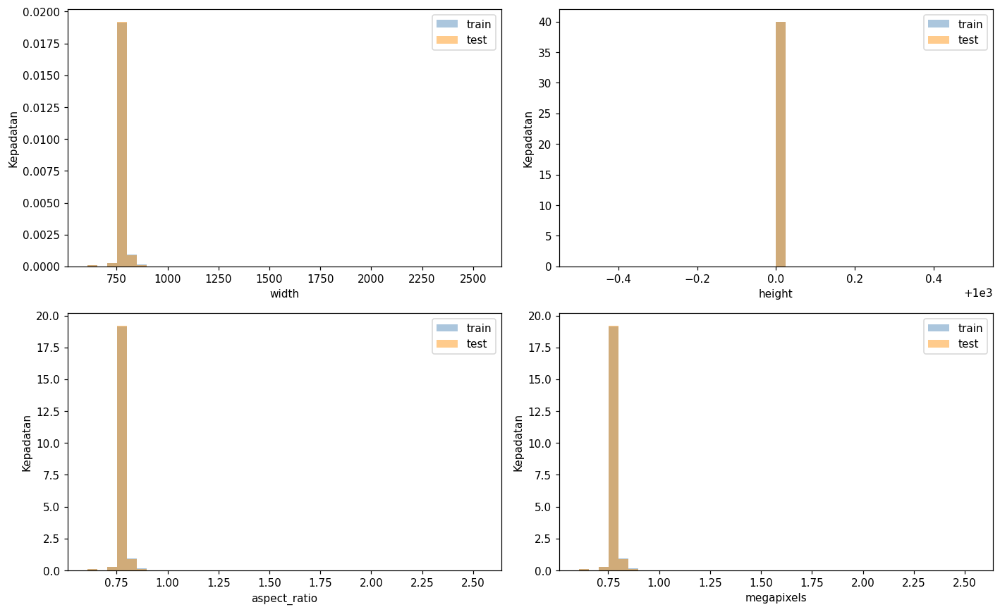

In [9]:
features = ['width','height','aspect_ratio','megapixels']
size_summary = valid_metadata.groupby('dataset')[features].agg(['min','median','max'])
display(size_summary.round(3))
size_summary.to_csv(OUTPUT_DIR / 'size_summary.csv')
for name in ['train','test']:
    print(f'Resolusi terbanyak: {name}')
    display(valid_metadata.loc[valid_metadata['dataset'].eq(name)]
            .groupby(['width','height']).size().reset_index(name='jumlah')
            .sort_values('jumlah',ascending=False).head(10))
color_summary = pd.crosstab(valid_metadata['dataset'],valid_metadata['color_mode'],normalize='index') * 100
print('Proporsi mode warna (%)')
display(color_summary.round(2))
color_summary.to_csv(OUTPUT_DIR / 'color_distribution_percent.csv')
print('Distribusi jumlah halaman TIFF')
display(pd.crosstab(valid_metadata['dataset'],valid_metadata['n_frames']))
fig,axes = plt.subplots(2,2,figsize=(13,8))
for ax,feature in zip(axes.ravel(),features):
    bins = np.histogram_bin_edges(valid_metadata[feature].dropna().astype(float),bins=40)
    for name,color in [('train','steelblue'),('test','darkorange')]:
        values = valid_metadata.loc[valid_metadata['dataset'].eq(name),feature].astype(float)
        ax.hist(values,bins=bins,density=True,alpha=.45,label=name,color=color)
    ax.set_xlabel(feature)
    ax.set_ylabel('Kepadatan')
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'train_test_comparison.png',dpi=150)
plt.show()
plt.close(fig)


## 8. Ukuran per kelas dan gambar ekstrem

Bandingkan ukuran gambar antarkelas, lalu tampilkan gambar dengan jumlah piksel paling sedikit serta rasio aspek paling kecil dan terbesar. Tampilkan pula sampel test.

Gambar ekstrem perlu dilihat sebelum menentukan preprocessing. Nilai ukuran yang ekstrem sendiri bukan alasan untuk menghapus sampel.


,jumlah,median_width,median_height,median_aspect_ratio
class_name,,,,
advertisement,2012,757.0,1000.0,0.757
budget,2004,771.0,1000.0,0.771
email,2013,754.0,1000.0,0.754
file_folder,2022,762.0,1000.0,0.762
form,2005,754.0,1000.0,0.754
handwritten,2026,754.0,1000.0,0.754
invoice,1982,762.0,1000.0,0.762
letter,1972,768.5,1000.0,0.768
memo,1994,762.0,1000.0,0.762


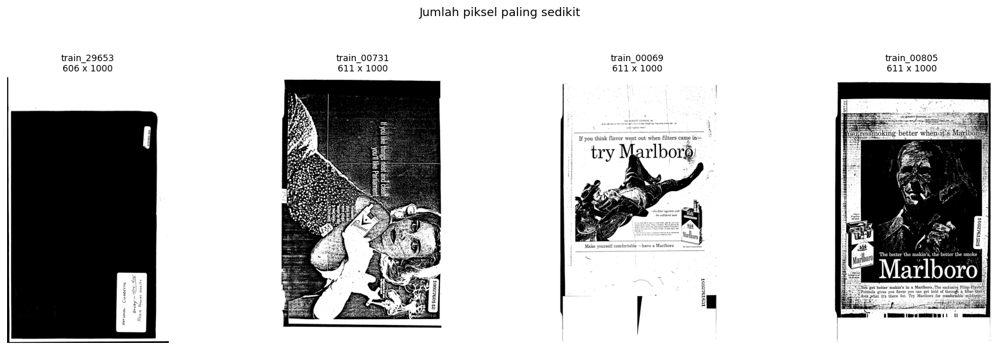

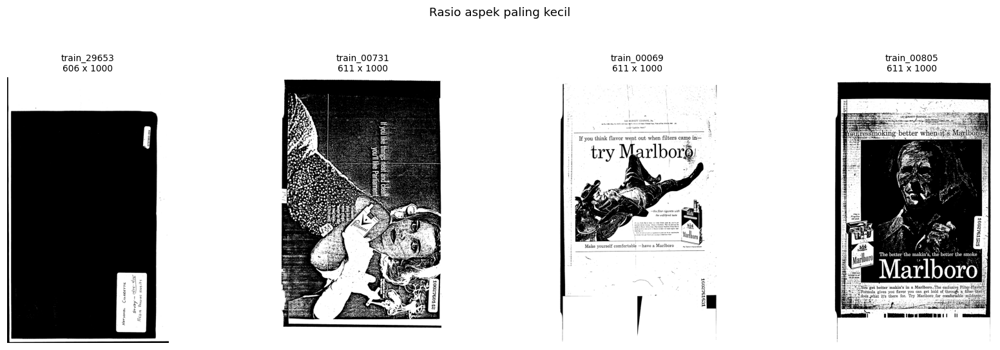

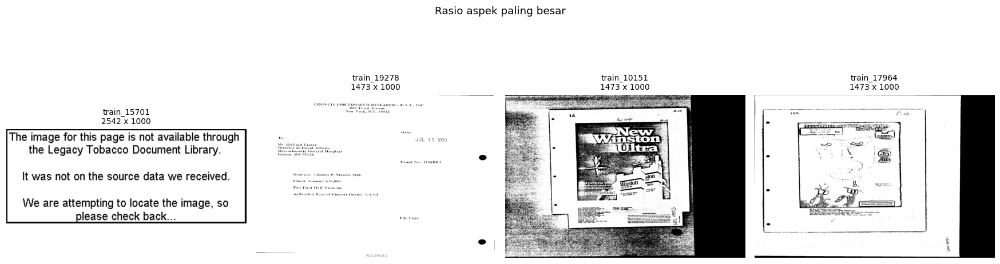

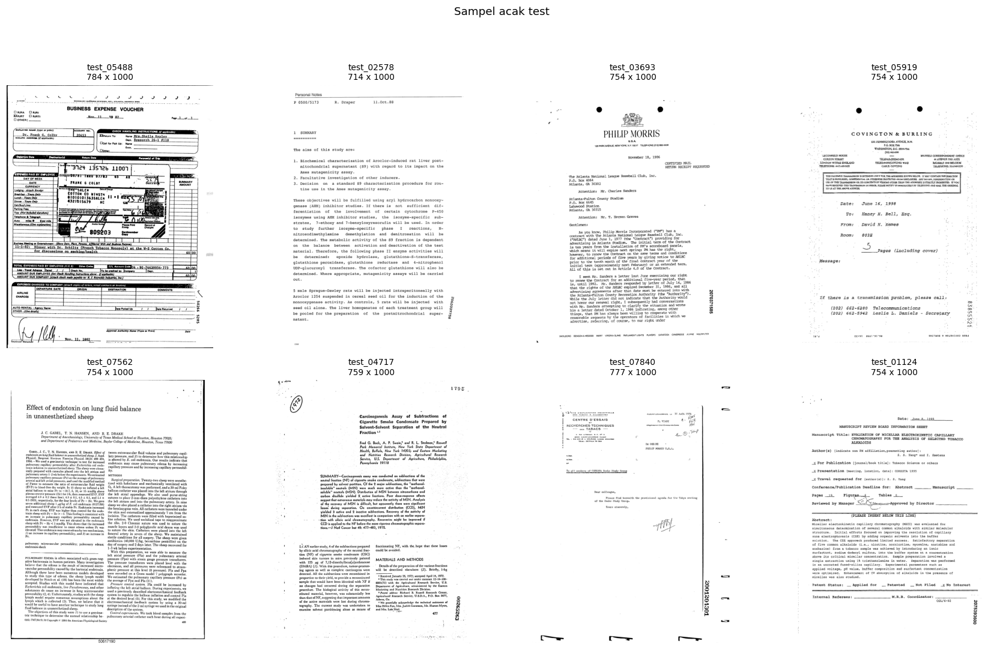

In [10]:
train_visual = train_df.merge(
    train_metadata[['id','width','height','megapixels','aspect_ratio','status']],
    on='id',how='left',validate='one_to_one')
valid_train_visual = train_visual.loc[train_visual['status'].eq('ok')]
class_size_summary = (valid_train_visual.groupby('class_name')
    .agg(jumlah=('id','size'),median_width=('width','median'),median_height=('height','median'),
         median_aspect_ratio=('aspect_ratio','median')).reindex(CLASS_NAMES))
display(class_size_summary.round(3))
class_size_summary.to_csv(OUTPUT_DIR / 'size_by_class.csv')
show_gallery(valid_train_visual.sort_values('megapixels'),'Jumlah piksel paling sedikit','smallest_images.png')
show_gallery(valid_train_visual.sort_values('aspect_ratio'),'Rasio aspek paling kecil','narrow_images.png')
show_gallery(valid_train_visual.sort_values('aspect_ratio',ascending=False),'Rasio aspek paling besar','wide_images.png')
show_gallery(test_df,'Sampel acak test','test_gallery.png',n=8,random_sample=True)
pd.DataFrame(gallery_errors,columns=['id','path','error']).drop_duplicates().to_csv(OUTPUT_DIR / 'gallery_errors.csv',index=False)


## 9. Ringkasan dan keputusan untuk pemodelan

Data memiliki 16 kelas dengan jumlah sampel yang relatif serupa. Satu file train gagal dibaca metadatanya dan perlu dicatat saat persiapan data model. Semua file test tersedia untuk pemeriksaan metadata.

Ukuran gambar bervariasi sehingga masukan model perlu diseragamkan. Eksperimen DiT berikutnya menggunakan resize halaman penuh ke 224 x 224 piksel, mengikuti ukuran masukan model. Pengaruh perubahan ukuran terhadap hasil klasifikasi dinilai pada validation.




In [11]:
error_counts = image_metadata.loc[image_metadata['status'].ne('ok'),'dataset'].value_counts()
summary = {
    'train_rows':int(len(train_df)), 'test_rows':int(len(test_df)),
    'observed_classes':int(train_df['class_name'].nunique()),
    'largest_class':str(class_counts.idxmax()), 'largest_class_count':int(class_counts.max()),
    'smallest_class':str(class_counts.idxmin()), 'smallest_class_count':int(class_counts.min()),
    'train_metadata_errors':int(error_counts.get('train',0)),
    'test_metadata_errors':int(error_counts.get('test',0)),
    'pixel_loading_checked':READ_PIXELS,
}
with open(OUTPUT_DIR / 'eda_summary.json','w',encoding='utf-8') as file:
    json.dump(summary,file,indent=2,ensure_ascii=False)
display(pd.DataFrame(summary.items(),columns=['pemeriksaan','hasil']))
lines = [
    '# Hasil EDA','',
    f'Jumlah baris train: {len(train_df):,}. Jumlah baris test: {len(test_df):,}.',
    f'Jumlah kategori ditemukan: {train_df["class_name"].nunique()}.',
    f'Kategori terbanyak: {class_counts.idxmax()} ({class_counts.max():,} gambar).',
    f'Kategori paling sedikit: {class_counts.idxmin()} ({class_counts.min():,} gambar).',
    f'File train gagal pada pemeriksaan metadata: {summary["train_metadata_errors"]}.',
    f'File test gagal pada pemeriksaan metadata: {summary["test_metadata_errors"]}.',
    '', '## Cakupan pemeriksaan','',
    'Pemuatan piksel halaman pertama: ' + ('diperiksa.' if READ_PIXELS else 'belum diperiksa secara menyeluruh.'),
    'Duplikasi piksel, ketepatan label, dan keterbacaan seluruh halaman TIFF belum diperiksa.',
    '', '## Hasil tersimpan','',
    'metadata_audit.csv, class_distribution.csv, image_metadata.csv, image_errors.csv,',
    'image_warnings.csv, size_summary.csv, size_by_class.csv, serta galeri PNG.',
]
(OUTPUT_DIR / 'eda_summary.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('Hasil EDA tersimpan di:',OUTPUT_DIR)


,pemeriksaan,hasil
0,train_rows,32003
1,test_rows,7994
2,observed_classes,16
3,largest_class,scientific_publication
4,largest_class_count,2056
5,smallest_class,questionnaire
6,smallest_class_count,1948
7,train_metadata_errors,1
8,test_metadata_errors,0
9,pixel_loading_checked,False


Hasil EDA tersimpan di: /kaggle/working/eda
